Using Colab cache for faster access to the 'animals10' dataset.
Path to dataset files: /kaggle/input/animals10/raw-img
Found 26179 files belonging to 10 classes.
Using 20944 files for training.
Found 26179 files belonging to 10 classes.
Using 5235 files for validation.
Classes: ['dog', 'horse', 'elephant', 'butterfly', 'chicken', 'cat', 'cow', 'sheep', 'spider', 'squirrel']
Number of classes: 10
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 161s 233ms/step - accuracy: 0.8588 - loss: 0.4554 - val_accuracy: 0.9509 - val_loss: 0.1633
Epoch 2/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 45s 68ms/step - accuracy: 0.9185 - loss: 0.2662 - val_accuracy: 0.9547 - val_loss: 0.1447
Epoch 3/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 44s 67ms/step - accuracy: 0.9205 - loss: 0.2546 - val_accuracy: 0.9543 - val_loss: 0.1474
Epoch 4/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 44s 68ms/step - accuracy: 0.9244 - loss: 0.2445 - val_accuracy: 0.9551 - val_loss: 0.1427
Epoch 5/5
655/655 ━━━━━━━━━━━━━━━━━━━━ 44s 67ms/step - accuracy: 0.9280 - loss: 0.2306 - val_accuracy: 0.9515 - val_loss: 0.1560
164/164 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step - accuracy: 0.9515 - loss: 0.1560

Test Loss    : 0.15599316358566284
Test Accuracy: 0.9514804482460022


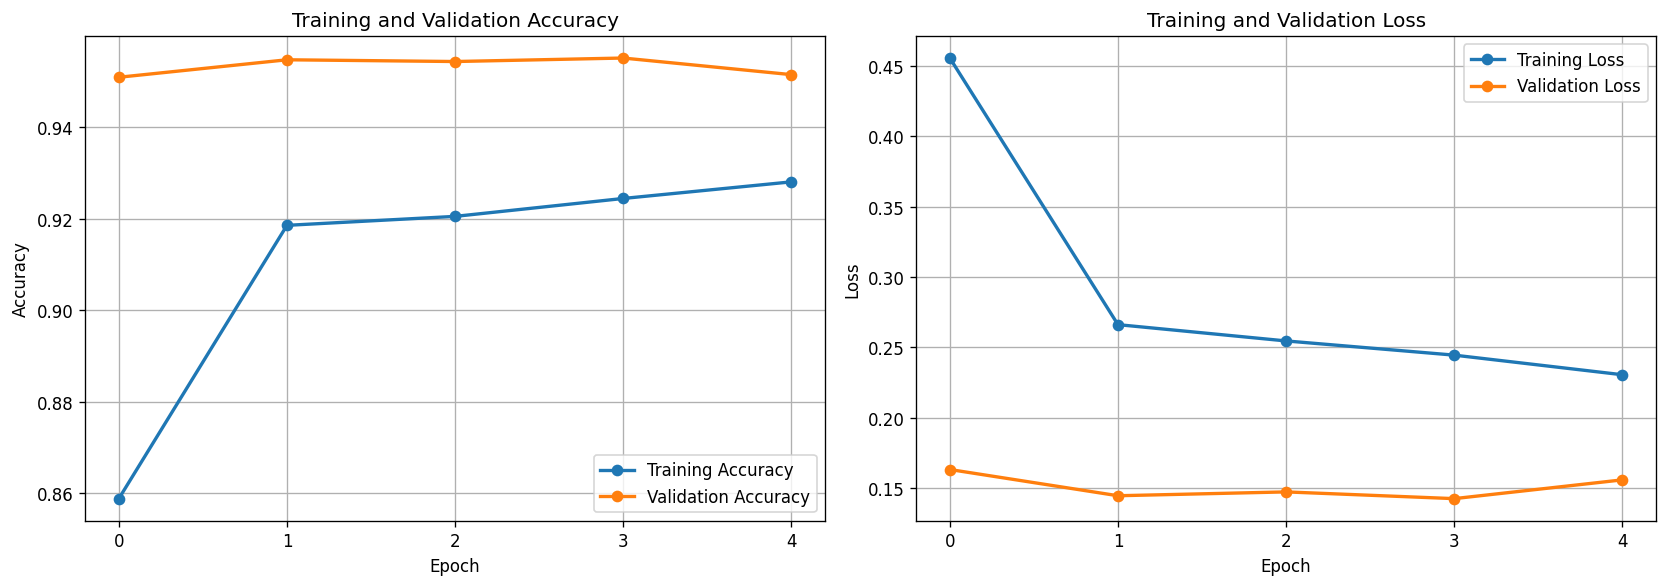

Upload an image of an animal:


Saving images (2).jpg to images (2).jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

Predicted Animal: cat
Probability: 99.86%

Softmax Probabilities:
dog: 0.00%
horse: 0.01%
elephant: 0.00%
butterfly: 0.00%
chicken: 0.01%
cat: 99.86%
cow: 0.00%
sheep: 0.00%
spider: 0.00%
squirrel: 0.11%


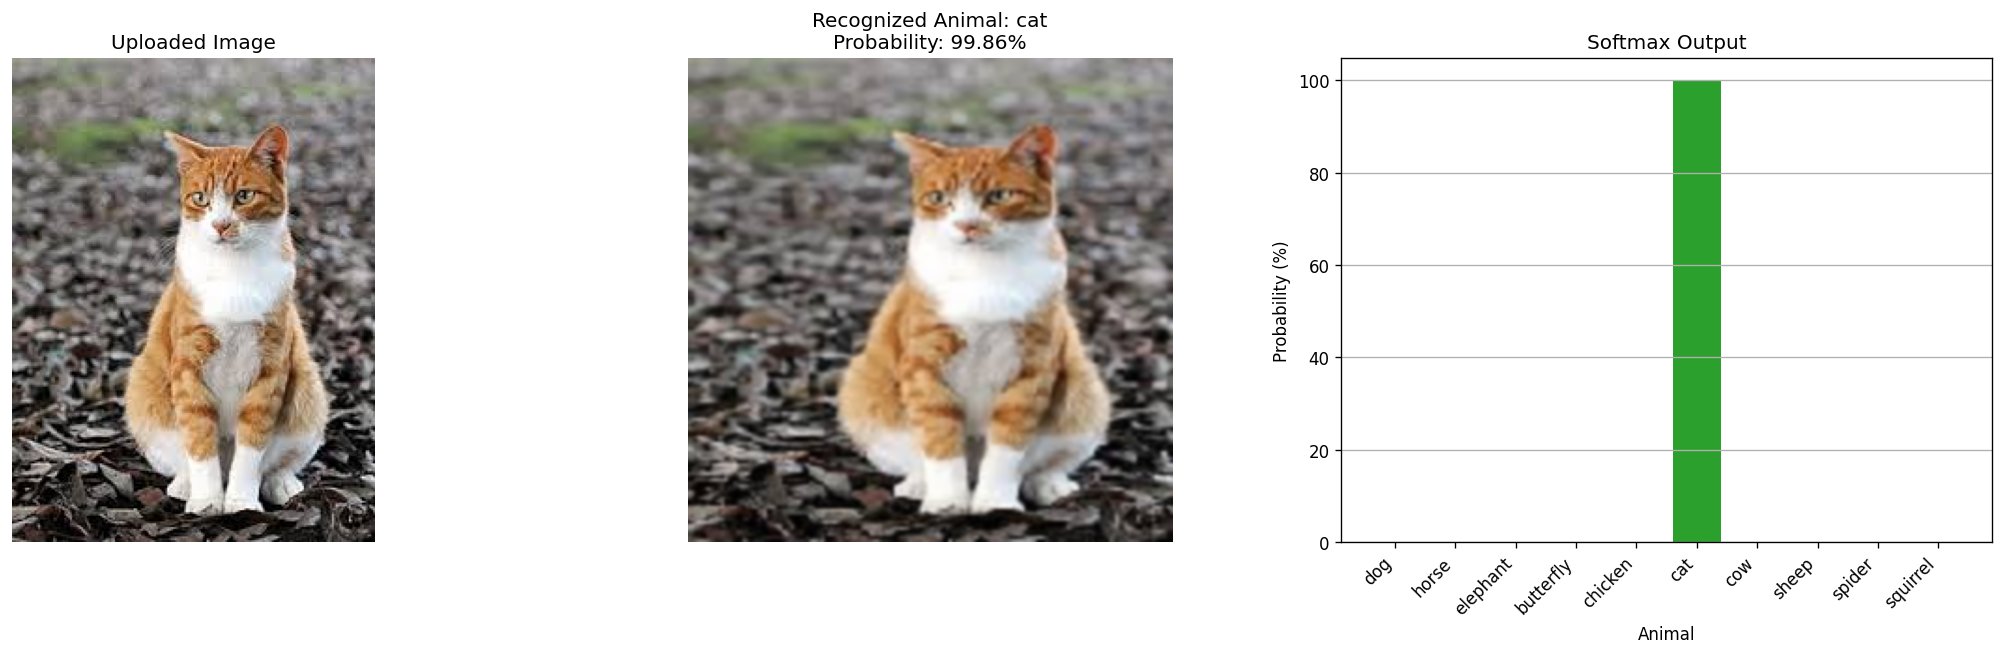

In [ ]:
import os
import kagglehub
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from google.colab import files

plt.rcParams["figure.dpi"] = 120

# Download dataset
path = kagglehub.dataset_download("alessiocorrado99/animals10")
dataset_path = os.path.join(path, "raw-img")

print("Path to dataset files:", dataset_path)

# Parameters
IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 5

# Load training data
train_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# Load validation data
validation_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# Convert Italian class names to English
italian_to_english = {
    "cane": "dog",
    "cavallo": "horse",
    "elefante": "elephant",
    "farfalla": "butterfly",
    "gallina": "chicken",
    "gatto": "cat",
    "mucca": "cow",
    "pecora": "sheep",
    "ragno": "spider",
    "scoiattolo": "squirrel"
}

class_names = [italian_to_english[c] for c in train_data.class_names]

print("Classes:", class_names)
print("Number of classes:", len(class_names))

# Prefetch data
train_data = train_data.prefetch(tf.data.AUTOTUNE)
validation_data = validation_data.prefetch(tf.data.AUTOTUNE)

# Load MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

# Build model
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Rescaling(1.0 / 127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Train model
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS
)

# Evaluate model
test_loss, test_acc = model.evaluate(validation_data)

print("\nTest Loss    :", test_loss)
print("Test Accuracy:", test_acc)

# Plot training and validation results
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    marker="o",
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    linewidth=2,
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(range(EPOCHS))
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    linewidth=2,
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(EPOCHS))
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Save model
model.save("animal_cnn_model.keras")

# Upload an image
print("Upload an image of an animal:")

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

# Load original image
original = image.load_img(image_path)

# Resize image
img = image.load_img(
    image_path,
    target_size=(IMG_SIZE, IMG_SIZE)
)

# Convert image to array
img_array = np.expand_dims(
    image.img_to_array(img),
    axis=0
)

# Make prediction
prediction = model.predict(img_array)[0]

predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = prediction[predicted_index] * 100

print("\nPredicted Animal:", predicted_class)
print("Probability: {:.2f}%".format(confidence))

# Display softmax probabilities
print("\nSoftmax Probabilities:")

for name, p in zip(class_names, prediction):
    print(f"{name}: {p * 100:.2f}%")

# Visualization
plt.figure(figsize=(18, 5.5))

# Uploaded image
plt.subplot(1, 3, 1)

plt.imshow(original)
plt.title("Uploaded Image")
plt.axis("off")

# Resized image with prediction
plt.subplot(1, 3, 2)

plt.imshow(img, interpolation="bicubic")

plt.title(
    f"Recognized Animal: {predicted_class}\n"
    f"Probability: {confidence:.2f}%"
)

plt.axis("off")

# Softmax output
plt.subplot(1, 3, 3)

colors = ["tab:blue"] * len(class_names)
colors[predicted_index] = "tab:green"

plt.bar(
    class_names,
    prediction * 100,
    color=colors
)

plt.title("Softmax Output")
plt.xlabel("Animal")
plt.ylabel("Probability (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()